# Mart review: Track A momentum rotation

Reads the mart layer (`data/marts/*.parquet` plus the dbt warehouse) through `market_data_pipeline.review.queries`.
The Excel workbook (`python -m market_data_pipeline.review`) uses the same functions, so both show the same numbers.

**Refresh first:** run the collectors, then `uv run python -m market_data_pipeline.build`.
The **test split is hidden** unless the build ran with `--include-test`. Leave it hidden until the strategy is frozen.

How to read this notebook:
- **Validation is the out-of-sample verdict.** Train is in-sample, so it is a sanity check only.
- A variant is kept only if it beats **all three baselines net of costs**: equal-weight, SPY buy-and-hold, and same-size random selection.
- Check robustness across the top-N grid. A good setting is one whose neighbours also work.

In [85]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

from market_data_pipeline.review import queries
from market_data_pipeline.settings import load_strategy

settings = load_strategy()
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_rows", 100)

# Validated categorical palette (fixed order, never cycled), recessive ink for axes and text.
SERIES = {"momentum": "#2a78d6", "equal_weight": "#eb6834", "spy_bh": "#1baf7a", "trend": "#6250d6"}
BAND, INK, MUTED, GRID = "#c3c2b7", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.titlelocation": "left",
    "axes.titlesize": 12, "axes.titleweight": "bold", "lines.linewidth": 2, "font.size": 10,
})
pct = mtick.PercentFormatter(1.0, decimals=0)

## 1. Data coverage and freshness

In [86]:
coverage = queries.coverage()
print(f"{len(coverage)} tickers, history from {coverage['first_date'].min()} to {coverage['last_date'].max()}")
coverage.head(12)   # shortest histories first: these join the ranking late (64-bar minimum)

47 tickers, history from 2016-01-04 00:00:00 to 2026-11-06 00:00:00


,ticker,asset_class,first_date,last_date,n_bars,last_ingested_at
0,SPCX,equity,2026-06-12,2026-11-06,103,2026-11-06 12:13:04.326052-08:00
1,IETH,equity,2025-10-02,2026-07-31,208,2026-11-06 12:13:04.326052-08:00
2,SNDK,equity,2025-02-13,2026-11-06,436,2026-11-06 12:13:04.326052-08:00
3,NFLX,equity,2024-10-29,2026-11-06,508,2026-11-06 12:13:04.326052-08:00
4,TSM,equity,2024-10-29,2026-11-06,508,2026-11-06 12:13:04.326052-08:00
5,GEV,equity,2024-04-02,2026-11-06,654,2026-11-06 12:13:04.326052-08:00
6,IBIT,equity,2024-01-11,2026-11-06,709,2026-11-06 12:13:04.326052-08:00
7,CEG,equity,2022-02-02,2026-11-06,1196,2026-11-06 12:13:04.326052-08:00
8,BTC/USD,crypto,2021-01-01,2026-11-06,2136,2026-11-06 12:13:04.326052-08:00
9,ETH/USD,crypto,2021-01-01,2026-11-06,2136,2026-11-06 12:13:04.326052-08:00


In [87]:
queries.collector_runs().head(10)

,run_id,source,dataset,status,row_count,file_count,min_date,max_date,started_at,finished_at,error
0,20261106T201657Z-fa52b225,deribit,options_chain,success,778,1,2026-11-06,2026-11-06,2026-11-06 12:16:57.243215-08:00,2026-11-06 12:16:58.193615-08:00,NaN
1,20261106T201323Z-d34e45fd,alpaca,options_chain,success,25324,1,2026-11-06,2026-11-06,2026-11-06 12:13:23.507604-08:00,2026-11-06 12:16:56.029709-08:00,NaN
2,20261106T201313Z-5408a827,fred,series,success,125828,1,1919-01-01,2026-11-06,2026-11-06 12:13:13.354631-08:00,2026-11-06 12:13:21.956702-08:00,NaN
3,20261106T201304Z-bb1b1d2e,alpaca,bars_1d,success,241,1,2026-07-27 04:00:00+00:00,2026-11-06 05:00:00+00:00,2026-11-06 12:13:04.326052-08:00,2026-11-06 12:13:12.219763-08:00,NaN
4,20261105T204441Z-d26315fb,deribit,options_chain,success,774,1,2026-11-05,2026-11-05,2026-11-05 12:44:41.362058-08:00,2026-11-05 12:44:42.257863-08:00,NaN
5,20261105T204121Z-db8c192c,alpaca,options_chain,success,24484,1,2026-11-05,2026-11-05,2026-11-05 12:41:21.883921-08:00,2026-11-05 12:44:40.209574-08:00,NaN
6,20261105T204111Z-09595ac2,fred,series,success,125816,1,1919-01-01,2026-11-05,2026-11-05 12:41:11.085144-08:00,2026-11-05 12:41:20.302526-08:00,NaN
7,20261105T204102Z-e9754533,alpaca,bars_1d,success,198,1,2026-07-27 04:00:00+00:00,2026-11-05 05:00:00+00:00,2026-11-05 12:41:02.822037-08:00,2026-11-05 12:41:09.969212-08:00,NaN
8,20261104T190407Z-217a3b24,deribit,options_chain,success,758,1,2026-11-04,2026-11-04,2026-11-04 11:04:07.235577-08:00,2026-11-04 11:04:08.092942-08:00,NaN
9,20261104T190136Z-dba836ff,alpaca,options_chain,success,24113,1,2026-11-04,2026-11-04,2026-11-04 11:01:36.320945-08:00,2026-11-04 11:04:06.044719-08:00,NaN


In [88]:
queries.split_summary()

,split,first_date,last_date,trading_days
0,train,2016-10-17,2023-09-28,1749
1,gap,2023-09-29,2025-05-05,42
2,validation,2023-10-30,2025-04-03,358
3,test,2025-05-06,2026-11-06,380


## 2. Today's momentum ranking
Daily features, so this ranking moves between rebalances. `mom_score` is the 3-month return divided by 3-month volatility.

In [89]:
queries.latest_ranks().head(15)

,date,ticker,asset_class,mom_rank,mom_score,ret_21,ret_63,ret_252,vol_63,dist_ma200,above_ma200,trend_risk_on,vix
0,2026-11-06,V,equity,1,0.787,0.127,0.172,0.253,0.218,0.228,True,True,28.180
1,2026-11-06,PG,equity,2,0.628,0.100,0.131,0.161,0.208,0.117,True,True,28.180
2,2026-11-06,XLV,equity,3,0.546,0.100,0.102,0.291,0.187,0.167,True,True,28.180
3,2026-11-06,COST,equity,4,0.532,0.114,0.108,0.134,0.203,0.087,True,True,28.180
4,2026-11-06,AAPL,equity,5,0.522,0.009,0.115,0.277,0.219,0.151,True,True,28.180
5,2026-11-06,BTC/USD,crypto,6,0.462,-0.072,0.186,-0.270,0.403,0.041,True,True,28.180
6,2026-11-06,IBIT,equity,7,0.457,-0.073,0.184,-0.272,0.403,0.039,True,True,28.180
7,2026-11-06,XLP,equity,8,0.386,0.082,0.070,0.222,0.181,0.077,True,True,28.180
8,2026-11-06,LLY,equity,9,0.347,0.164,0.107,0.480,0.308,0.241,True,True,28.180
9,2026-11-06,ETH/USD,crypto,10,0.342,-0.098,0.192,-0.348,0.561,0.029,True,True,28.180


## 3. Keep or cut: variants vs the three baselines

In [90]:
verdicts = queries.keep_or_cut()
verdicts[verdicts["split"] == "validation"][[
    "variant", "n_rebalances", "net_cagr", "sharpe", "max_drawdown", "random_pctile",
    "equal_weight_cagr", "spy_bh_cagr", "random_p50_cagr", "verdict"]]

,variant,n_rebalances,net_cagr,sharpe,max_drawdown,random_pctile,equal_weight_cagr,spy_bh_cagr,random_p50_cagr,verdict
8,momentum_top1,18,1.110,2.467,-0.093,0.975,0.368,0.220,0.268,PROMISING: only 18 rebalances (< 36)
9,momentum_top1_trend,18,1.110,2.467,-0.093,0.975,0.368,0.220,0.268,PROMISING: only 18 rebalances (< 36)
10,momentum_top2,18,0.622,1.809,-0.107,0.875,0.368,0.220,0.317,CUT: loses to a baseline
11,momentum_top2_trend,18,0.662,1.913,-0.102,0.905,0.368,0.220,0.317,CUT: loses to a baseline
12,momentum_top3,18,0.404,1.369,-0.204,0.615,0.368,0.220,0.332,CUT: loses to a baseline
13,momentum_top3_trend,18,0.485,1.624,-0.162,0.755,0.368,0.220,0.332,CUT: loses to a baseline
14,momentum_top5,18,0.325,1.380,-0.140,0.465,0.368,0.220,0.339,CUT: loses to a baseline
15,momentum_top5_trend,18,0.364,1.527,-0.130,0.580,0.368,0.220,0.339,CUT: loses to a baseline


In [91]:
perf = queries.performance()
perf[~perf["variant"].str.contains(r"_p(?:05|95)$")][[
    "split", "variant", "n_rebalances", "net_cagr", "gross_cagr", "max_drawdown", "sharpe", "ann_vol",
    "avg_turnover", "hit_rate", "base_rate", "mean_rank_ic", "random_pctile"]]

,split,variant,n_rebalances,net_cagr,gross_cagr,max_drawdown,sharpe,ann_vol,avg_turnover,hit_rate,base_rate,mean_rank_ic,random_pctile
0,train,equal_weight,83.000,0.235,0.235,-0.263,1.153,0.202,0.017,0.586,0.586,NaN,NaN
1,train,momentum_top1,83.000,0.190,0.214,-0.500,0.678,0.351,1.578,0.554,0.586,0.040,0.570
2,train,momentum_top1_trend,83.000,0.148,0.171,-0.500,0.577,0.349,1.530,0.518,0.586,0.040,0.505
3,train,momentum_top2,83.000,0.278,0.299,-0.356,0.909,0.329,1.301,0.566,0.586,0.040,0.860
4,train,momentum_top2_trend,83.000,0.238,0.258,-0.356,0.830,0.317,1.277,0.562,0.586,0.040,0.740
5,train,momentum_top3,83.000,0.402,0.423,-0.248,1.362,0.278,1.185,0.598,0.586,0.040,0.990
6,train,momentum_top3_trend,83.000,0.339,0.359,-0.248,1.219,0.270,1.161,0.601,0.586,0.040,0.970
7,train,momentum_top5,83.000,0.371,0.389,-0.157,1.456,0.238,1.034,0.600,0.586,0.040,0.995
8,train,momentum_top5_trend,83.000,0.323,0.341,-0.268,1.324,0.233,1.063,0.601,0.586,0.040,0.970
10,train,random_top1_p50,83.000,0.146,0.174,-0.468,0.567,0.335,1.940,0.590,0.586,NaN,NaN


## 4. Equity curves vs baselines
Net of costs, with equal-weight sizing reset at each rebalance. The grey band is the 5th to 95th percentile of same-size random portfolios. The dashed line marks where validation starts.

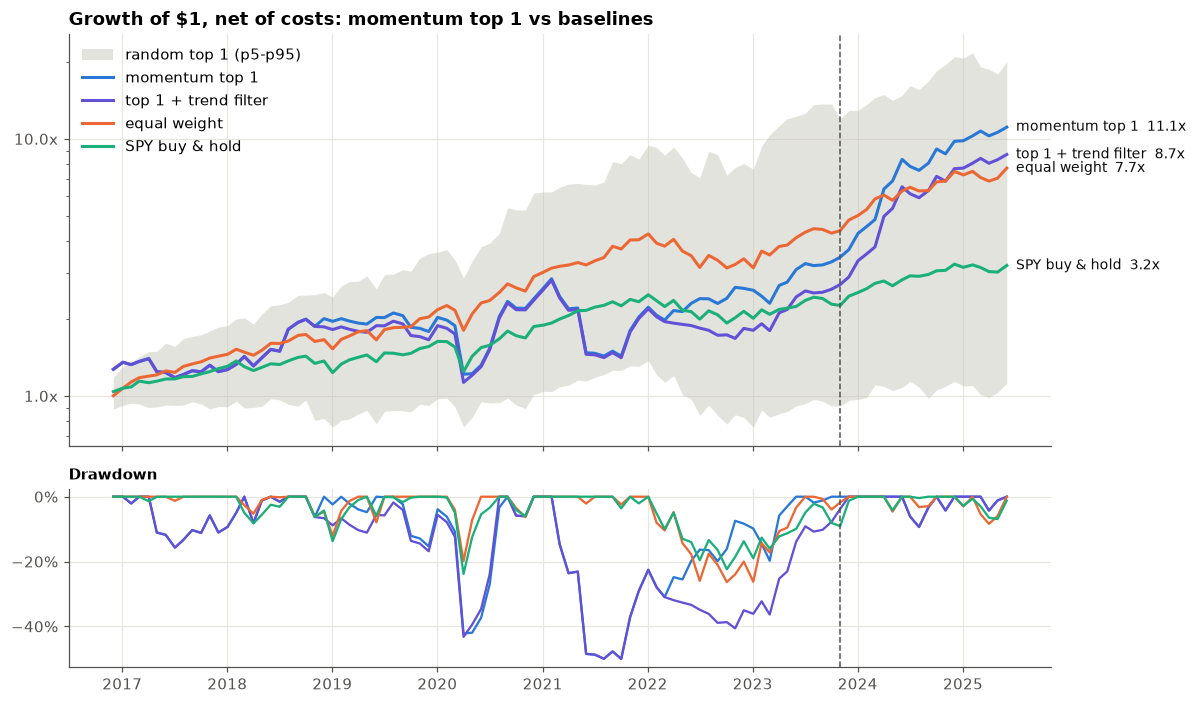

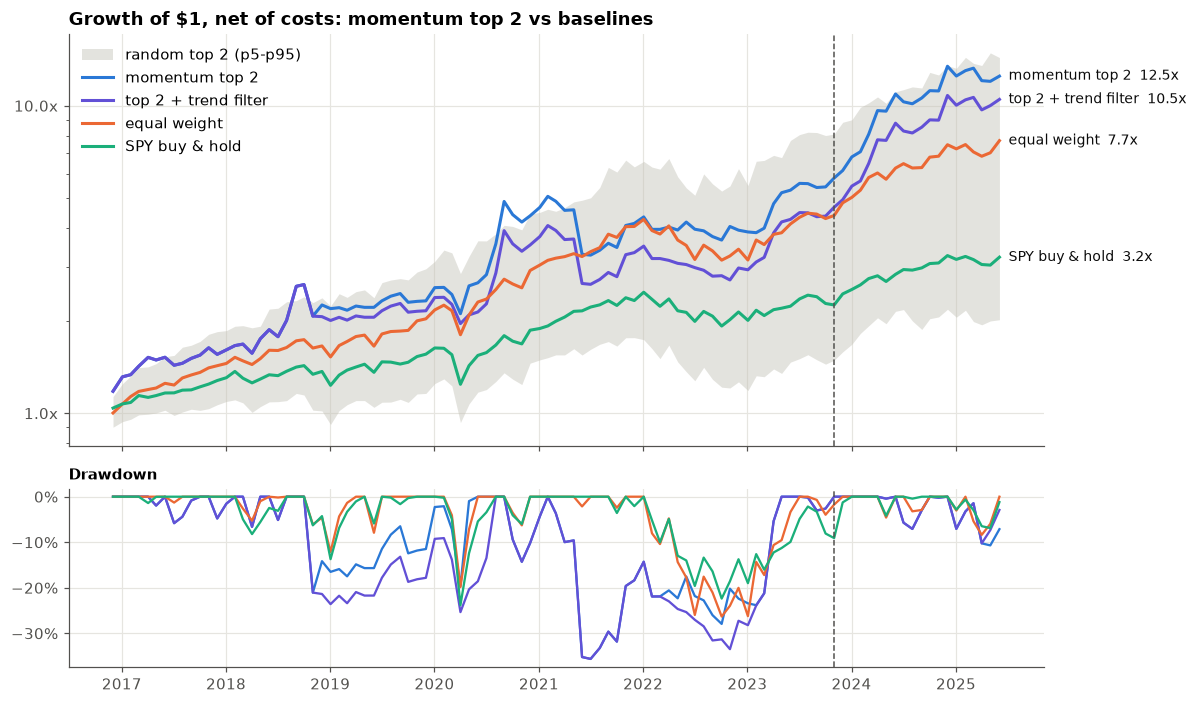

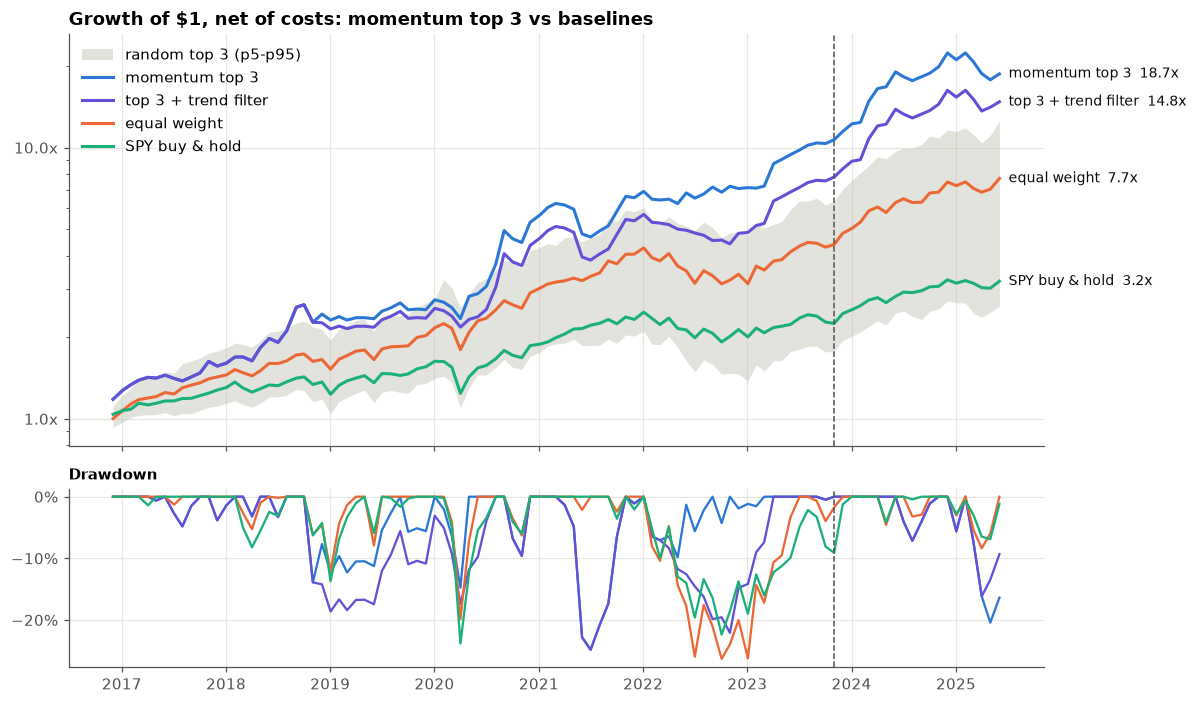

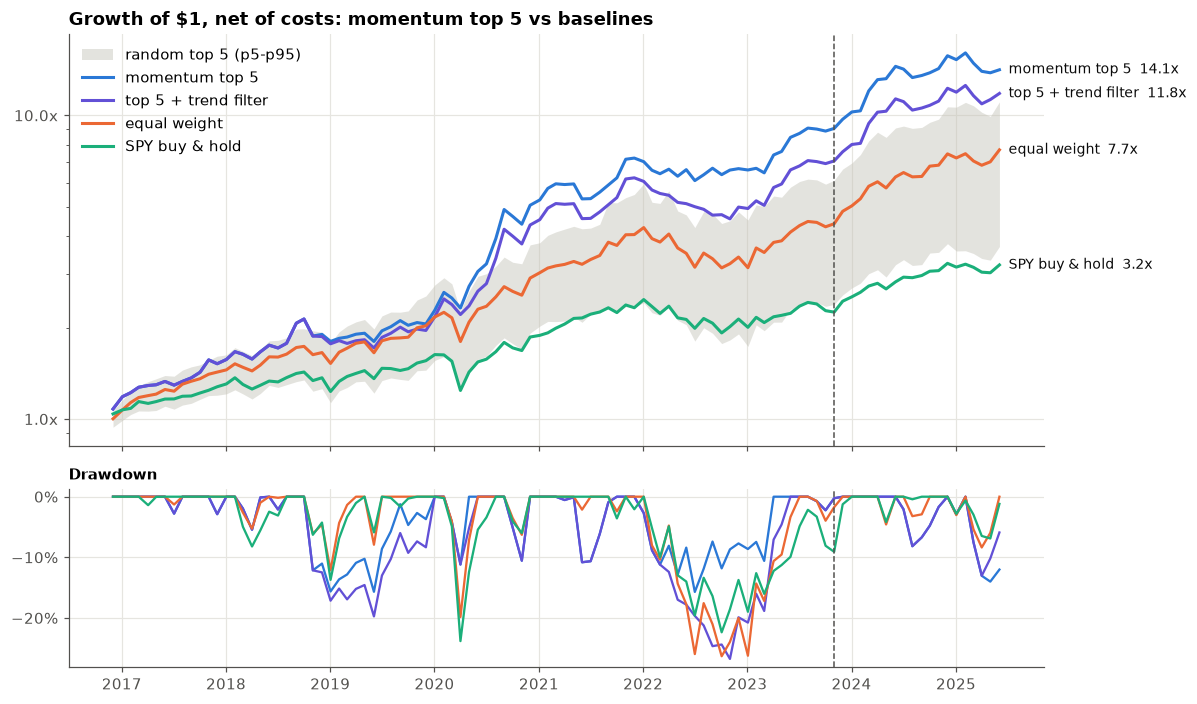

In [92]:
curves = queries.equity_curve()
splits = queries.split_summary().set_index("split")
validation_start = pd.Timestamp(splits.loc["validation", "first_date"]) if "validation" in splits.index else None

def plot_equity(top_n: int, log: bool = True):
    fig, (ax, dd) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
    band = curves[curves["variant"].isin([f"random_top{top_n}_p05", f"random_top{top_n}_p95"])]
    lo = band[band["variant"].str.endswith("p05")].set_index("exit_date")["equity"]
    hi = band[band["variant"].str.endswith("p95")].set_index("exit_date")["equity"]
    ax.fill_between(lo.index, lo, hi.reindex(lo.index), color=BAND, alpha=0.45, linewidth=0, label=f"random top {top_n} (p5-p95)")
    lines = [(f"momentum_top{top_n}", f"momentum top {top_n}", SERIES["momentum"]),
             (f"momentum_top{top_n}_trend", f"top {top_n} + trend filter", SERIES["trend"]),
             ("equal_weight", "equal weight", SERIES["equal_weight"]),
             ("spy_bh", "SPY buy & hold", SERIES["spy_bh"])]
    for variant, label, color in lines:
        c = curves[curves["variant"] == variant].set_index("exit_date")
        ax.plot(c.index, c["equity"], color=color, label=label)
        ax.annotate(f"{label}  {c['equity'].iloc[-1]:.1f}x", (c.index[-1], c["equity"].iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", color=INK, fontsize=9, va="center")
        dd.plot(c.index, c["drawdown"], color=color, linewidth=1.5)
    if log:
        ax.set_yscale("log")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.1f}x"))
    ax.set_title(f"Growth of $1, net of costs: momentum top {top_n} vs baselines")
    ax.legend(loc="upper left", frameon=False)
    dd.yaxis.set_major_formatter(pct)
    dd.set_title("Drawdown", fontsize=10)
    for a in (ax, dd):
        if validation_start is not None:
            a.axvline(validation_start, color=MUTED, linestyle="--", linewidth=1)
    fig.tight_layout()
    plt.show()

for n in settings["top_n_grid"]:
    plot_equity(n)

## 5. Quintile gradient
This plots the mean forward return (`target_horizon` days) for each momentum quintile at every rebalance. Quintile 1 is the strongest momentum. A working signal steps down from Q1 to Q5.

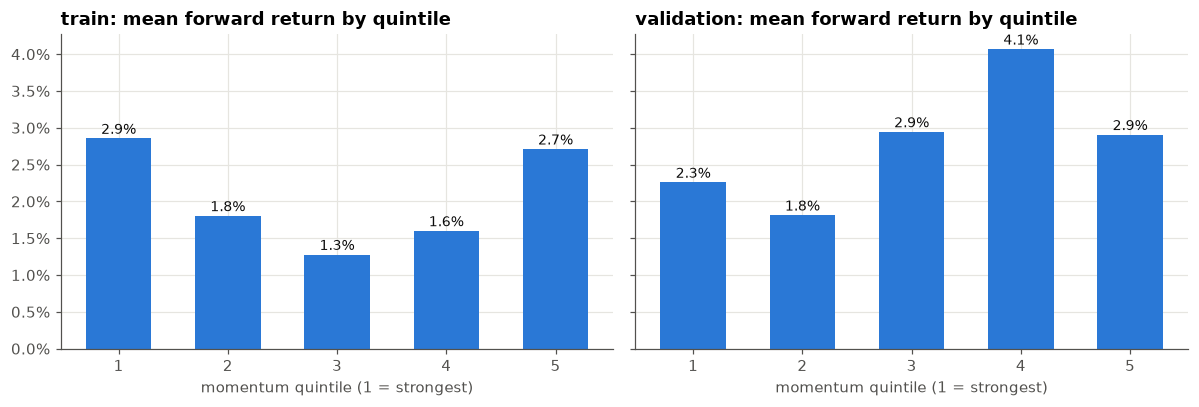

,split,quintile,n_rebalances,mean_fwd_ret,median_fwd_ret,share_positive
0,train,1,83,0.029,0.026,0.711
1,train,2,83,0.018,0.026,0.723
2,train,3,83,0.013,0.015,0.627
3,train,4,83,0.016,0.020,0.663
4,train,5,83,0.027,0.019,0.627
5,validation,1,18,0.023,0.020,0.556
6,validation,2,18,0.018,0.022,0.667
7,validation,3,18,0.029,0.036,0.722
8,validation,4,18,0.041,0.039,0.722
9,validation,5,18,0.029,0.032,0.667


In [93]:
q = queries.quintiles()
fig, axes = plt.subplots(1, q["split"].nunique(), figsize=(11, 3.8), sharey=True, squeeze=False)
for ax, (split, g) in zip(axes[0], q.groupby("split", sort=False)):
    ax.bar(g["quintile"].astype(str), g["mean_fwd_ret"], color=SERIES["momentum"], width=0.6)
    for x, y in zip(g["quintile"].astype(str), g["mean_fwd_ret"]):
        ax.annotate(f"{y:.1%}", (x, y), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color=INK)
    ax.set_title(f"{split}: mean forward return by quintile")
    ax.set_xlabel("momentum quintile (1 = strongest)")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
fig.tight_layout()
plt.show()
q

## 6. Rank IC over time
The Spearman correlation between `mom_score` and the next holding-period return, measured across the eligible names at each rebalance. If it is consistently above zero, the ranking carries information.

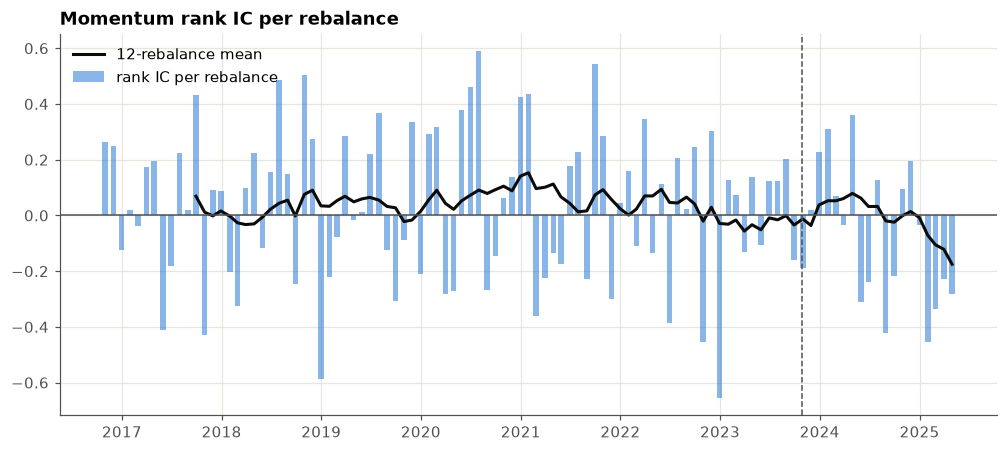

,mean,std,count
split,,,
gap,-0.221,0.087,2
train,0.040,0.275,83
validation,-0.059,0.251,18


In [94]:
ic = queries.rank_ic()
ic["rebalance_date"] = pd.to_datetime(ic["rebalance_date"])
fig, ax = plt.subplots()
ax.bar(ic["rebalance_date"], ic["rank_ic"], width=20, color=SERIES["momentum"], alpha=0.55, label="rank IC per rebalance")
ax.plot(ic["rebalance_date"], ic["rank_ic"].rolling(12).mean(), color=INK, linewidth=2, label="12-rebalance mean")
ax.axhline(0, color=MUTED, linewidth=1)
if validation_start is not None:
    ax.axvline(validation_start, color=MUTED, linestyle="--", linewidth=1)
ax.set_title("Momentum rank IC per rebalance")
ax.legend(loc="upper left", frameon=False)
plt.show()
ic.groupby("split")["rank_ic"].agg(["mean", "std", "count"])

## 7. Robustness across the top-N grid
The stable-region check: a parameter is trustworthy only if its neighbours also beat the baselines. A single good cell surrounded by weak ones is noise.

In [95]:
grid = verdicts.assign(
    top_n=verdicts["variant"].str.extract(r"top(\d+)", expand=False).astype(int),
    filter=verdicts["variant"].str.endswith("_trend").map({True: "trend", False: "base"}),
)
for metric in ("net_cagr", "sharpe", "random_pctile"):
    display(grid.pivot_table(index=["split", "filter"], columns="top_n", values=metric).style
            .format("{:.1%}" if metric != "sharpe" else "{:.2f}")
            .background_gradient(cmap="Blues", axis=None)
            .set_caption(metric))

## 8. Current holdings
This is the portfolio each variant holds since the latest rebalance. Its period has not finished, so it is not in the performance figures.

In [96]:
queries.latest_holdings()

,variant,ticker,weight,mom_score,score_rank,rebalance_date,entry_date
0,equal_weight,XLE,0.022,0.917,1,2026-10-30,2026-11-02
1,equal_weight,XLV,0.022,0.829,2,2026-10-30,2026-11-02
2,equal_weight,LLY,0.022,0.828,3,2026-10-30,2026-11-02
3,equal_weight,AAPL,0.022,0.727,4,2026-10-30,2026-11-02
4,equal_weight,V,0.022,0.695,5,2026-10-30,2026-11-02
5,equal_weight,TSLA,0.022,0.607,6,2026-10-30,2026-11-02
6,equal_weight,BTC/USD,0.022,0.569,7,2026-10-30,2026-11-02
7,equal_weight,PG,0.022,0.569,8,2026-10-30,2026-11-02
8,equal_weight,SOL/USD,0.022,0.563,9,2026-10-30,2026-11-02
9,equal_weight,IBIT,0.022,0.516,10,2026-10-30,2026-11-02


## Caveats to keep in mind
- **Survivorship and selection bias:** the universe was hand-picked in 2026, so the names that won are in it. That inflates every variant **and** every baseline. Compare against equal-weight and random rather than reading absolute CAGR.
- **History:** Alpaca equities start in 2016 and crypto in 2021, so crypto only competes from 2021.
- **Correlated names:** IBIT/IETH track BTC/ETH, so a top-N can hold the same exposure twice.
- **Costs** are a flat per-side rate (config/strategy.yaml). Slippage on large orders is not modelled.
- **Turnover** ignores drift between rebalances, which slightly understates real trading.